## Dia 5 — Percentis sem regra escondida

### Situação

Uma central de atendimento quer conhecer as esperas mais longas e investigar casos incomuns. Você deverá resumir a distribuição e usar um boxplot para sinalizar observações que merecem atenção. Um sinal estatístico, porém, não comprova que o registro está errado.

### Dados disponíveis

O arquivo `esperas.csv` contém 12 tempos na coluna `minutos`. Calcule os quantis por interpolação linear, equivalente a `quantile(interpolation="linear")` no pandas. Defina o intervalo interquartil como `IQR = Q3 - Q1`. Para sinalizar observações, use os limites `Q1 - 1,5 × IQR` e `Q3 + 1,5 × IQR`.

### Sua tarefa

1. Calcule o primeiro quartil, a mediana, o terceiro quartil e o percentil 90. Registre a convenção de quantis utilizada.
2. Calcule o IQR e os dois limites de sinalização. Liste os tempos que ficaram estritamente fora desses limites.
3. Construa um boxplot coerente com os quartis e limites adotados. Se a biblioteca usar outra convenção, configure o gráfico ou forneça as estatísticas já calculadas.
4. Escreva uma orientação para investigar os casos sinalizados, mantendo todos os registros na base original.

### Entrega

Inclua uma tabela de quantis e limites, a lista dos valores sinalizados, o boxplot e sua orientação de investigação.

### Confira seu avanço

- [ ] Os quantis estão entre o mínimo e o máximo e aparecem em ordem crescente ou igual.
- [ ] A lista e o gráfico sinalizam os valores de acordo com os limites calculados.
- [ ] Minha explicação diferencia um valor incomum, um erro confirmado e um caso raro válido.

### Interpretação

1. O percentil 90 observado garante um prazo para o próximo atendimento? Explique.
2. Como duas bibliotecas poderiam produzir quartis diferentes para os mesmos dados?

### Leituras de apoio

Fávero e Belfiore, Manual de Análise de Dados, cap. 2; Steven Dutt-Ross, Manual de Análise de Dados, cap. 9.


## Minha estratégia

Explique como pretende abordar o problema.

## Resolução

Os arquivos de dados estão nesta pasta. Se necessário, confira o diretório de execução com `Path.cwd()`. Acrescente células conforme precisares.

In [ ]:
# 1. Calcule o primeiro quartil, a mediana, o terceiro quartil e o percentil 90. 
# Registre a convenção de quantis utilizada.

import pandas as pd

dados_tempo = pd.read_csv("esperas.csv")
dados_tempo

# Convenção utilizada -> quantis por interpolação linear.
# interpolação linear: quando a posição do quantil cai entre dois valores ordenados, 
# o cálculo usa esses dois valores para obter um resultado intermediário.

print(dados_tempo.minutos.quantile(0.25)) # 1º Quartil (25%)
print(dados_tempo.minutos.quantile(0.50)) # 2º Quartil / Mediana (50%)
print(dados_tempo.minutos.quantile(0.75)) # 3º Quartil (75%)
print(dados_tempo.minutos.quantile(0.90)) # Percentil 90 (90%)

5.0
7.5
14.25
21.6


In [12]:
# 2. Calcule o IQR e os dois limites de sinalização. Liste os tempos que ficaram estritamente fora desses limites.

# `IQR = Q3 - Q1`. Para sinalizar observações, use os limites `Q1 - 1,5 × IQR` e `Q3 + 1,5 × IQR`.

Q1 = dados_tempo.minutos.quantile(0.25)
Q3 = dados_tempo.minutos.quantile(0.75)
IQR = Q3 - Q1

# limites

limite_1 = Q1 - 1.5 * IQR
limite_2 = Q3 + 1.5 * IQR

print(IQR)
print(limite_1)
print(limite_2)


# fora do limite

fora_dos_limites = dados_tempo[~(dados_tempo['minutos'].between(limite_1, limite_2))]

display(dados_tempo)
for indice, linha in fora_dos_limites.iterrows():
    print(f"Índice do Outlier: {indice} | Valor fora do limite: {linha['minutos']}")




9.25
-8.875
28.125


,minutos
0,3
1,4
2,5
3,5
4,6
5,7
6,8
7,10
8,13
9,18


Índice do Outlier: 11 | Valor fora do limite: 41


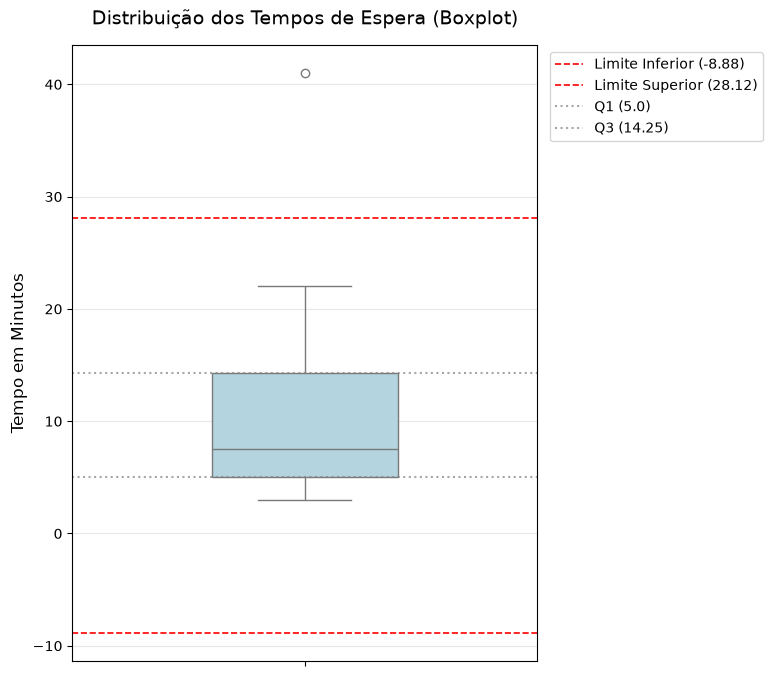

In [ ]:
# 3. Construa um boxplot coerente com os quartis e limites adotados. Se a biblioteca usar outra convenção, 
# configure o gráfico ou forneça as estatísticas já calculadas.

import matplotlib.pyplot as plt


# ■■■ BOXPLOT DOS TEMPOS DE ESPERA ■■■

# ====== Mediana e valores dentro dos limites

mediana = dados_tempo['minutos'].quantile(
    0.50,
    interpolation='linear',
)

dentro_dos_limites = dados_tempo.loc[
    dados_tempo['minutos'].between(limite_1, limite_2),
    'minutos',
]


# ====== Estatísticas para o boxplot

estatisticas = [{
    'label': 'Tempo de espera',
    'q1': Q1,
    'med': mediana,
    'q3': Q3,
    'whislo': dentro_dos_limites.min(),
    'whishi': dentro_dos_limites.max(),
    'fliers': fora_dos_limites['minutos'].tolist(),
}]


# ====== Construção do gráfico

fig, ax = plt.subplots(figsize=(7, 5))

ax.bxp(
    estatisticas,
    showfliers=True,
)

ax.set_title('Distribuição dos tempos de espera')
ax.set_ylabel('Tempo de espera (minutos)')
ax.grid(axis='y', alpha=0.3)

plt.show()

In [21]:
# 4. Estruturação do dicionário onde chaves viram colunas

dados = {
    'Q1': [Q1],
    'Q3': [Q3],
    'IQR': [IQR],
    'Limite Superior': [limite_2],
    'Limite Inferior': [limite_1],
    # Mantém a lista de outliers compactada em uma única célula
    'Valores Fora do Limite': [fora_dos_limites['minutos'].tolist()],
    'Média': [dados_tempo['minutos'].mean()],
    'Mediana': [dados_tempo['minutos'].quantile(0.50)],
    'P90': [dados_tempo['minutos'].quantile(0.90, interpolation='linear')],
}

# Cria o DataFrame diretamente (cada chave vira uma coluna automatica)
tabela = pd.DataFrame(dados)
display(tabela)



,Q1,Q3,IQR,Limite Superior,Limite Inferior,Valores Fora do Limite,Média,Mediana,P90
0,5.0,14.25,9.25,28.125,-8.875,[41],11.833333,7.5,21.6


Orientação: O tempo de 41 minutos ficou acima do limite superior e, por isso, deve ser investigado. A central pode consultar os registros desse atendimento para verificar se houve algum erro na anotação do horário ou se aconteceu alguma situação que aumentou a espera. Se for confirmado um erro, a correção deve ser documentada. Se o tempo estiver correto, ele representa um caso incomum, mas válido. Em qualquer situação, os registros originais devem ser mantidos.

## Resultados e interpretação

1. O percentil 90 observado garante um prazo para o próximo atendimento?

Não. O percentil 90 de 21,6 minutos foi calculado usando as 12 esperas observadas. Ele pode servir como uma referência para estimar esperas futuras, mas não garante quanto tempo o próximo atendimento vai levar. Além disso, temos poucos registros para saber se esse resultado representa bem os atendimentos futuros.

2. Como duas bibliotecas poderiam produzir quartis diferentes para os mesmos dados?

Duas bibliotecas podem usar convenções diferentes para calcular a posição dos quartis. Quando essa posição fica entre dois valores ordenados, uma regra pode calcular um valor intermediário, enquanto outra pode escolher um dos valores observados. Nesta atividade, usamos a interpolação linear.

## Conferência dos critérios

Registre as evidências de conclusão e as dúvidas que restaram.